<>:200: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:206: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:200: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:206: SyntaxWarning: "is not" with a literal. Did you mean "!="?


/tmp/ipykernel_3966228/4247216068.py:200: SyntaxWarning: "is not" with a literal. Did you mean "!="?
  if plot_type is not 'location':
/tmp/ipykernel_3966228/4247216068.py:206: SyntaxWarning: "is not" with a literal. Did you mean "!="?
  if plot_type is not 'location':


M1a: all
labels b4:  ['McScan', 'MOSEG', '\\textbf{WERM}']
labels after:  ['McScan', 'MOSEG', '\\textbf{WERM}']


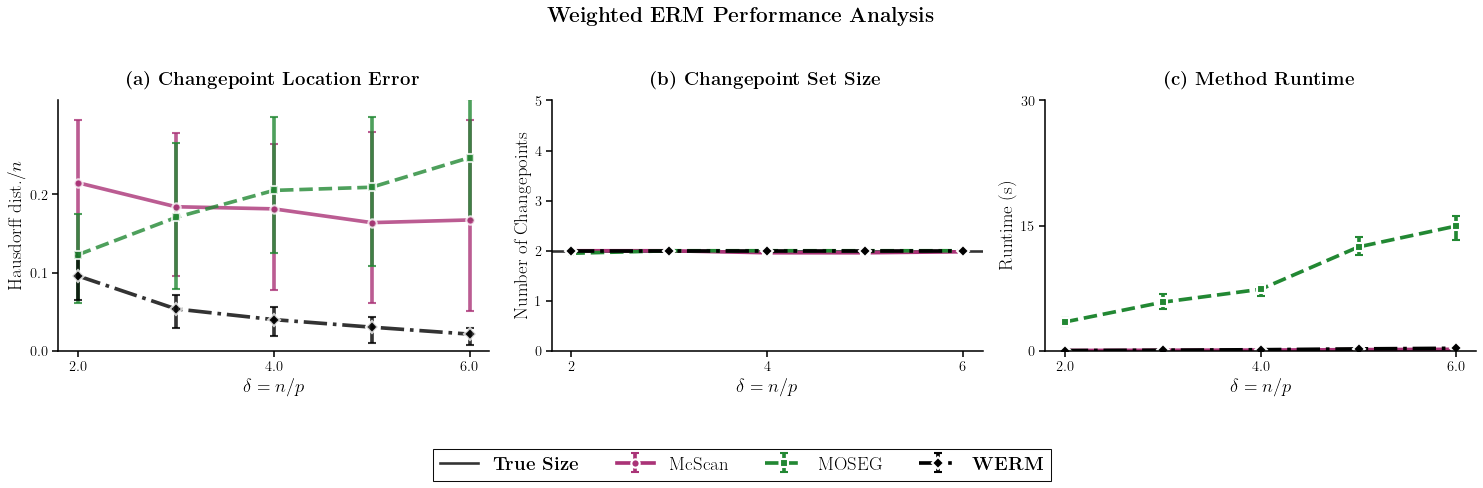

M1a: location
labels b4:  ['McScan', 'MOSEG', '\\textbf{WERM}']
labels after:  ['McScan', 'MOSEG', '\\textbf{WERM}']


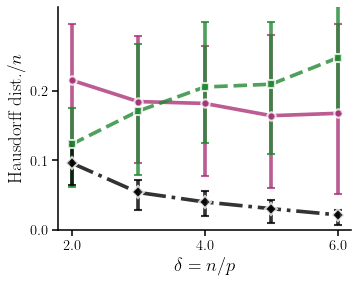

M1a: size
labels b4:  ['McScan', 'MOSEG', '\\textbf{WERM}']
labels after:  ['McScan', 'MOSEG', '\\textbf{WERM}']


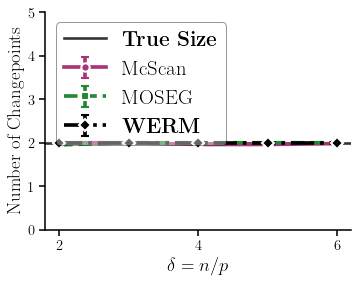

M1a: runtime
labels b4:  ['McScan', 'MOSEG', '\\textbf{WERM}']
labels after:  ['McScan', 'MOSEG', '\\textbf{WERM}']


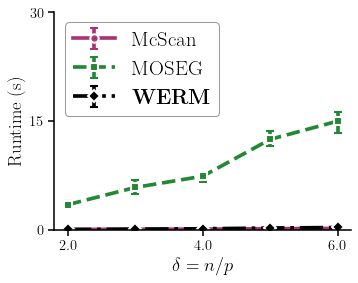

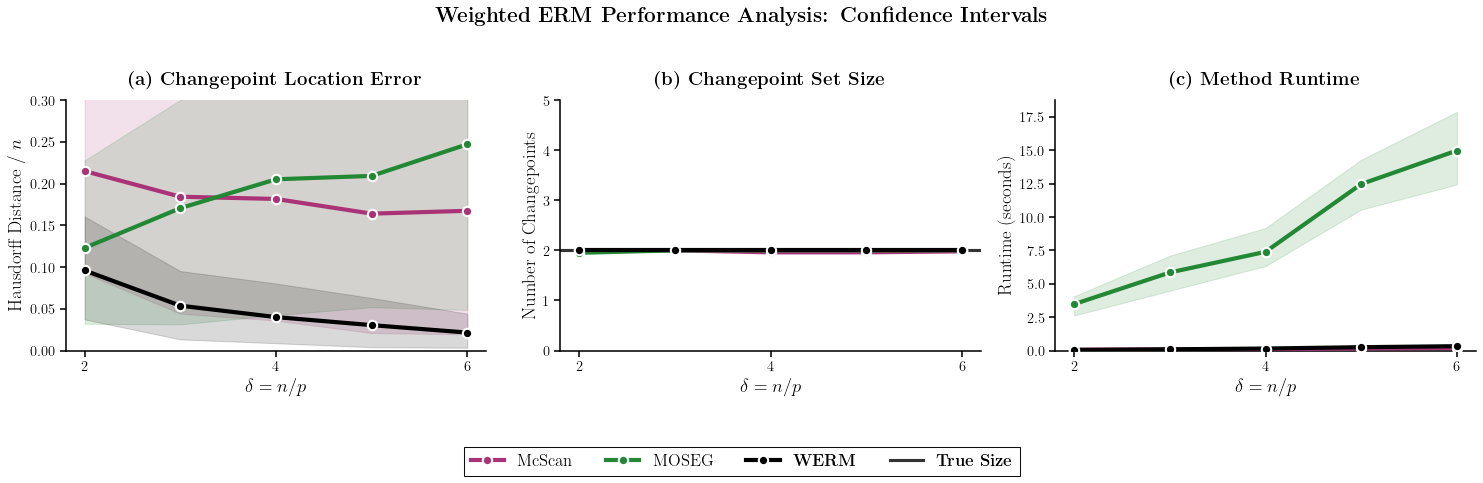

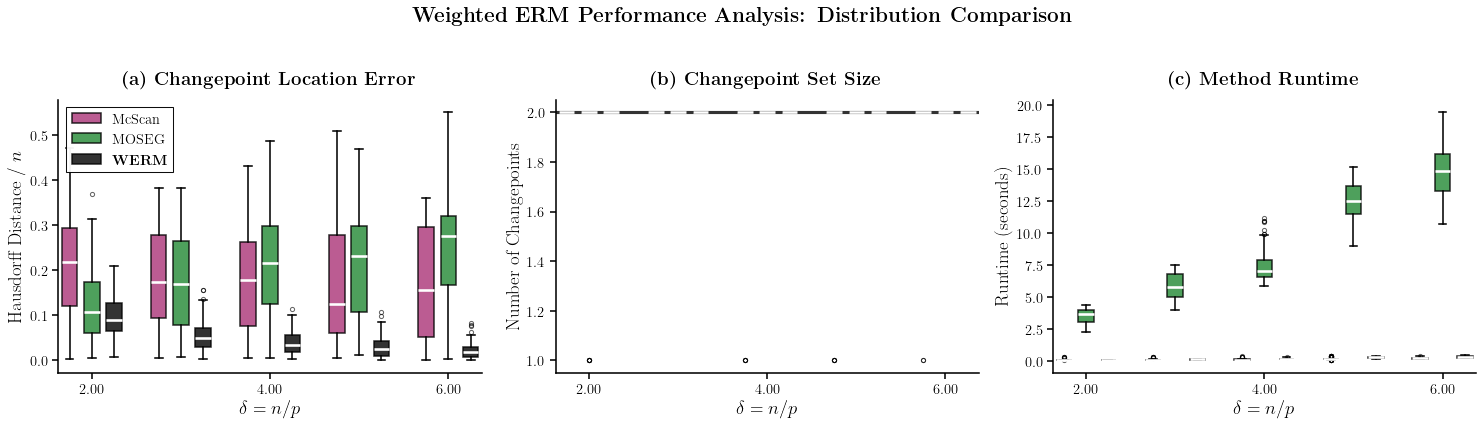

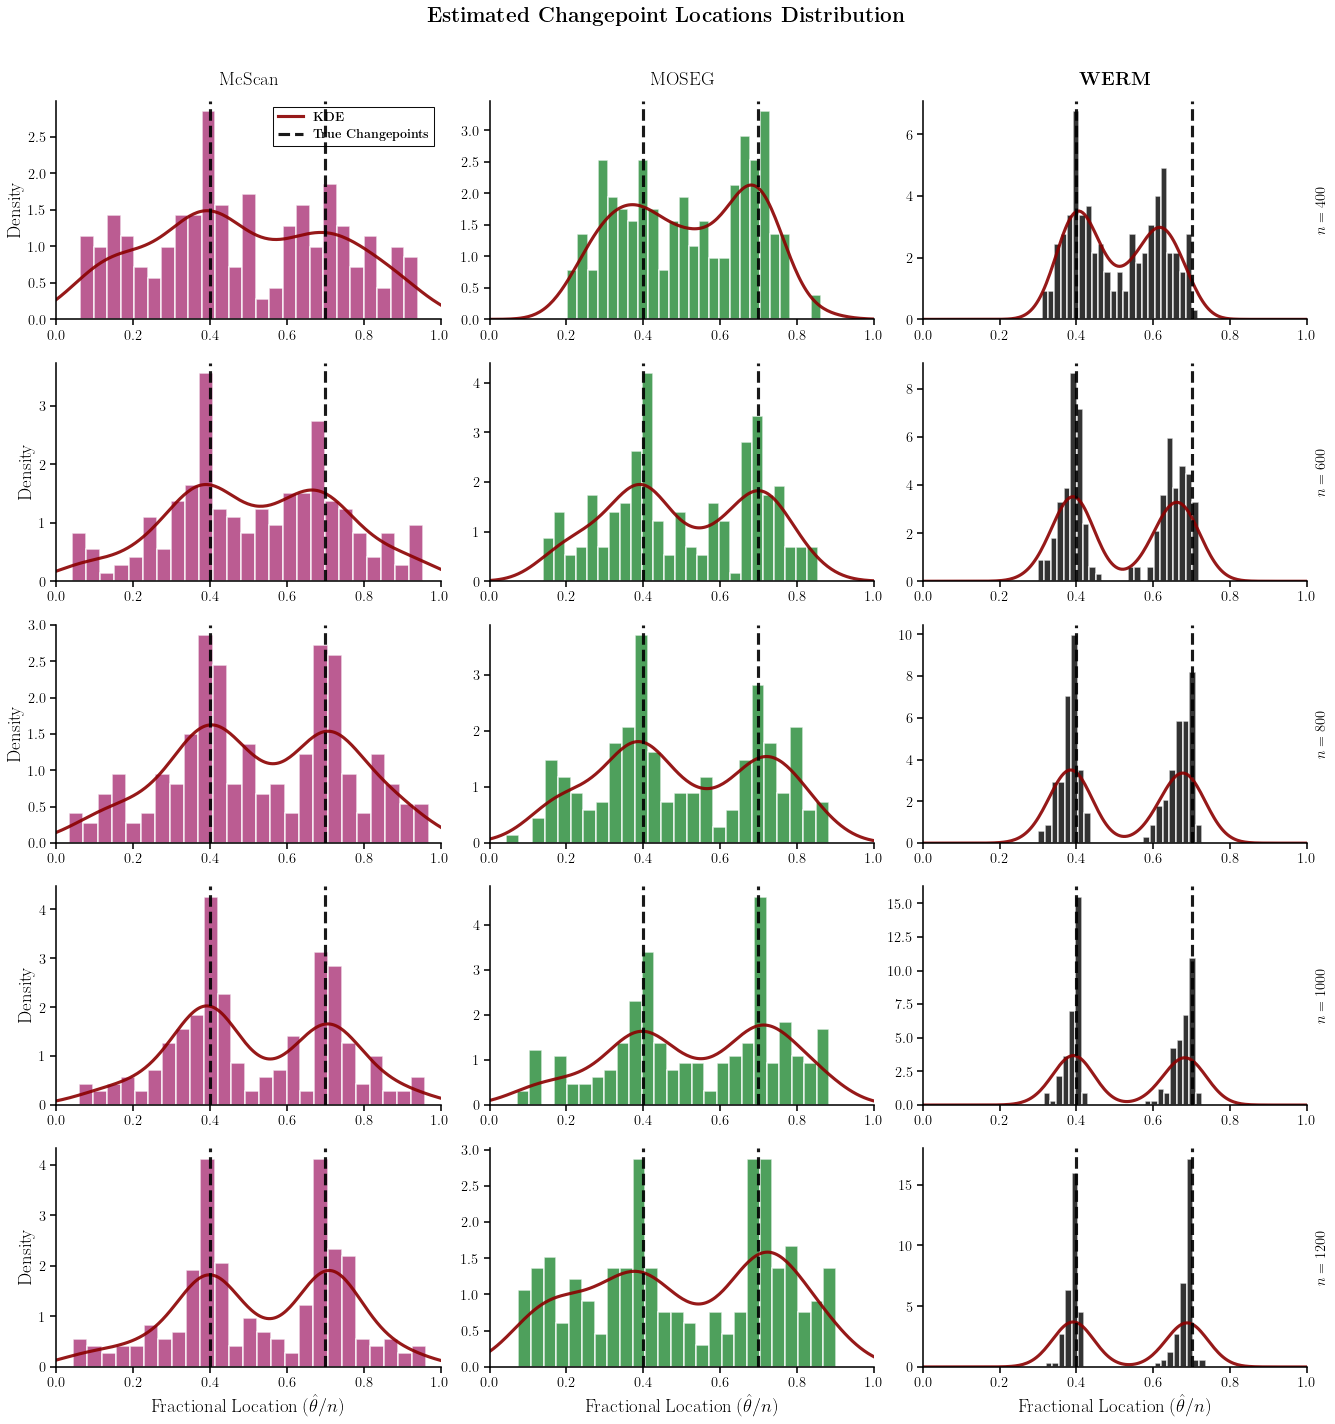

In [1]:
import os, pickle, time, logging
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
plt.switch_backend('module://matplotlib_inline.backend_inline')
main_logger = logging.getLogger('M1a-original-plots')
FINAL_RESULT_FILE = 'results/M1_upsample_final_M1a_native_fixedcount_seed42_100trials.pkl'
if os.environ.get('WERM_SMOKE') == '1':
    FINAL_RESULT_FILE = FINAL_RESULT_FILE.replace('.pkl', '_smoke.pkl')
with open(FINAL_RESULT_FILE, 'rb') as handle:
    payload = pickle.load(handle)
results, params = payload['results'], payload['params']
p, L = params['p'], params['L']
noise_std, random_seed = params['noise_std'], params['random_seed']
num_trials = params['num_trials']
δ_list = np.asarray(params['delta_list'])
fractional_chgpt_locations = np.asarray(params['fractional_chgpt_locations'])
methods_to_evaluate = [{'name': 'McScan', 'label': 'McScan', 'color': '#AA3377', 'marker': 'o', 'linestyle': '--', 'linewidth': 1.5, 'zorder': 5}, {'name': 'MOSEG', 'label': 'MOSEG', 'color': '#228833', 'marker': '^', 'linestyle': '-.', 'linewidth': 1.5, 'zorder': 5}, {'name': 'WERM-unp', 'label': '\\textbf{WERM}', 'color': 'black', 'marker': '*', 'linestyle': '-', 'linewidth': 2.5, 'zorder': 10}]
method_names_list = [m['name'] for m in methods_to_evaluate]
PAL = [m['color'] for m in methods_to_evaluate]
method_colors_map = {m['name']: m['color'] for m in methods_to_evaluate}
# Filter both metric rows and indexed histogram records without changing saved data.
_keep = np.flatnonzero(δ_list >= 2.0)
_index_map = {int(old): new for new, old in enumerate(_keep)}
results = dict(results)
for _method in method_names_list:
    for _metric in ('haus', 'size', 'runtime'):
        _key = f'{_metric}_{_method}'
        results[_key] = np.asarray(results[_key])[_keep]
for _key in ['true_chgpts'] + [f'chgpts_{m}' for m in method_names_list]:
    results[_key] = [(_index_map[int(i)], cp) for i, cp in results[_key] if int(i) in _index_map]
δ_list = δ_list[_keep]

plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',  # or 'xelatex', 'lualatex'
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,      # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,      # Enable LaTeX rendering
    'axes.linewidth': 1.5,    # Thicker axes
    'axes.labelsize': 18,     # Larger axis labels
    'axes.titlesize': 18,     # Larger titles
    'xtick.labelsize': 14,    # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,    # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': False,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 75,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})
x_y_label_fontsize = 18
def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles"""
    means = np.mean(data, axis=1)
    p25 = np.percentile(data, 25, axis=1)
    p75 = np.percentile(data, 75, axis=1)
    
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    
    if np.any(lower_errors < 0) or np.any(upper_errors < 0):
        std_errs = np.std(data, axis=1)
        return [std_errs, std_errs]
    
    return [lower_errors, upper_errors]

def plot_with_asymmetric_errors_publication(plot_type='all'):
    """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
    if plot_type == 'all':
        fig, axs = plt.subplots(1, 3, figsize=(20, 6))
        fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
    else:
        fig, axs = plt.subplots(1, 1, figsize=(5, 4.0))
    
    # Use method_names_list from the loaded/generated params
    methods = method_names_list
    colors = PAL[:len(methods)] # Use as many colors as methods
    
    # Define markers and linestyles to match the number of methods
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
    
    labels = [method['label'] for method in methods_to_evaluate] # Use labels from methods_to_evaluate
    print("labels b4: ", labels)
    labels = ['McScan', 'MOSEG', '\\textbf{WERM}']
    # labels = ['McScan', 'MOSEG', 'WERM']
    print("labels after: ", labels)
    
    # Hausdorff Distance Plot
    if plot_type == 'all' or plot_type == 'location':
        if plot_type == 'all': ax = axs[0]
        elif plot_type == 'location': ax = axs
        for i, method_name in enumerate(methods):
            data = results[f'haus_{method_name}']
            means = np.mean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
                        alpha=0.8)
        
        ax.set_ylim((0, 0.32))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Hausdorff dist./$n$', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
        
        # Cleaner x-axis with fewer ticks
        ax.set_xticks(δ_list[::2])  # Show every other tick
        # Set the xticks label size larger for better readability
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]], fontsize=14)
        # Cleaner y-axis with fewer ticks
        ax.set_yticks(np.array([0, 0.1, 0.2]))
        ax.set_yticklabels([f"{y:.1f}" for y in np.array([0, 0.1, 0.2])], fontsize=14)
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Changepoint Set Size Plot
    if plot_type == 'all' or plot_type == 'size':
        if plot_type == 'all': ax = axs[1]
        elif plot_type == 'size': ax = axs

        for i, method_name in enumerate(methods):
            data = results[f'size_{method_name}']
            means = np.mean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                   linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        ax.set_ylim((0, L + 2))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Number of Changepoints', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
        
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Runtime Plot
    if plot_type == 'all' or plot_type == 'runtime':
        if plot_type == 'all': ax = axs[2]
        elif plot_type == 'runtime': ax = axs
        for i, method_name in enumerate(methods):
            data = results[f'runtime_{method_name}']
            means = np.mean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        ax.set_ylim(bottom=0)
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Runtime (s)', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
        
        ax.set_xticks(δ_list[::2])
        # Set the xticks label size larger for better readability
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]], fontsize=14)
        # Cleaner y-axis with fewer ticks
        ax.set_yticks(np.array([0, 15, 30]))
        ax.set_yticklabels([f"{y:.0f}" for y in np.array([0, 15, 30])], fontsize=14)
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    if plot_type == 'all':
        # Single legend for all subplots
        handles, labels_leg = axs[1].get_legend_handles_labels()
        if plot_type is not 'location':
            fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                    ncol=len(methods)+1, fontsize=x_y_label_fontsize, frameon=True,
                    edgecolor='black', framealpha=0.95)
        plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    else:
        if plot_type is not 'location':
            ax.legend(loc='best', prop={'size': 20}, fancybox = True, framealpha = 0.4)
        fig.tight_layout()
    
    # plt.show() # Removed plt.show() as per the original structure that saves then shows
    return fig, axs

def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]
    
    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        
        for method_idx, method_name in enumerate(methods):
            data = results[f'{metric}_{method_name}']
            means = np.mean(data, axis=1)
            
            # Calculate confidence intervals (10th and 90th percentiles)
            p10 = np.percentile(data, 10, axis=1)
            p90 = np.percentile(data, 90, axis=1)
            
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)
            
            # Plot confidence band first (so it's behind the line)
            ax.fill_between(δ_list, p10, p90, color=colors[method_idx],
                            alpha=0.15, zorder=1)
            
            # Plot mean line with markers
            ax.plot(δ_list, means, color=colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)
        
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Cleaner axes
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]
    
    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        
        # Create box plots for each delta value
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            
            for method_idx, method_name in enumerate(methods):
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                box_data.append(data)
                box_positions.append(delta_idx * (len(methods) + 1) + method_idx) # Adjusted spacing
                box_colors.append(colors[method_idx])
            
            # Create publication-ready box plots
            bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                            patch_artist=True, showfliers=True,
                            flierprops=dict(marker='o', markersize=4, alpha=0.6),
                            medianprops=dict(color='white', linewidth=2.5),
                            boxprops=dict(linewidth=1.5),
                            whiskerprops=dict(linewidth=1.5),
                            capprops=dict(linewidth=1.5))
            
            # Color the boxes
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.8)
                patch.set_edgecolor('black')
        
        # Set x-axis labels - only show every other delta for cleanliness
        # Adjust delta_positions calculation
        delta_positions = [i * (len(methods) + 1) + (len(methods) - 1) / 2.0 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])  # Every other position
        ax.set_xticklabels([f'{d:.2f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Add legend (only for first subplot)
        if ax_idx == 0:
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=labels[i])
                               for i in range(len(methods))]
            ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                      frameon=True, edgecolor='black', framealpha=0.95)
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
        
        # Clean axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=['ext']):
    """
    Publication-ready changepoint location histograms
    Updated to use method_names_list and method_labels from methods_to_evaluate.
    """
    
    # Create method_names and method_colors dictionaries dynamically from methods_to_evaluate
    method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
    # method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    
    # Filter methods based on methods_to_plot_names
    current_methods = [method for method in methods_to_evaluate if method['name'] in methods_to_plot_names]
    current_method_names = [method['name'] for method in current_methods]

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    
    fig, axes = plt.subplots(len(selected_deltas), len(current_methods),
                             figsize=(6*len(current_methods), 4*len(selected_deltas)))
    
    # Handle subplot configurations
    if len(selected_deltas) == 1 and len(current_methods) == 1:
        axes = np.array([[axes]])
    elif len(current_methods) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                 fontsize=20, y=0.98)
    
    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # Collect changepoints for the current method and delta
            all_chgpts = []
            chgpts_data_for_method = results.get(f'chgpts_{method_name}', [])
            for res_delta_idx, chgpts_list in chgpts_data_for_method:
                if res_delta_idx == delta_idx:
                    # chgpts_list can be a list of arrays or just a list/array
                    for chgpts in chgpts_list:
                        if hasattr(chgpts, '__len__') and len(chgpts) > 0:
                            chgpts_array = np.array(chgpts)
                            valid_chgpts = chgpts_array[chgpts_array != -1]
                            for chgpt in valid_chgpts:
                                fractional_chgpt = chgpt / n
                                all_chgpts.append(fractional_chgpt)
                        elif np.isscalar(chgpts) and chgpts != -1:
                            fractional_chgpt = chgpts / n
                            all_chgpts.append(fractional_chgpt)
            
            # Create publication-ready histogram
            if len(all_chgpts) > 0:
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map[method_name],
                                                density=True, edgecolor='white',
                                                linewidth=1.5)
                
                # Add KDE overlay if we have enough points
                if len(all_chgpts) > 8:
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
                
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')
            
            # True changepoints with thicker lines
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', linewidth=3,
                           alpha=0.9, zorder=10,
                           label=r'\textbf{True Changepoints}' if i == 0 else "")
            
            ax.set_xlim(0, 1)
            
            # Only label bottom row and leftmost column
            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=18)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=18)
            
            # Method name as title for top row
            if row == 0:
                ax.set_title(f'{method_names_map[method_name]}', fontsize=18, pad=15)
            
            # Add n value annotation
            if col == len(current_methods)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')
            
            # Clean axes
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
            
            # Add legend for first subplot if there are changepoints
            if row == 0 and col == 0 and len(all_chgpts) > 0:
                legend = ax.legend(loc='upper right', fontsize=12, frameon=True,
                                   edgecolor='black', framealpha=0.95)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()
for plot_type in ('all', 'location', 'size', 'runtime'):
    print('M1a:', plot_type)
    plot_with_asymmetric_errors_publication(plot_type=plot_type)
    plt.show()
plot_with_confidence_bands_publication()
plot_with_boxplots_publication()
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
